# Sleep Staging — 09: Tamaño de contexto temporal

**Objetivo:** evaluar cuánto contexto temporal conviene utilizar manteniendo fija la arquitectura temporal definida en NB8.

Se comparan ventanas centradas de 3, 5 y 7 epochs:

```text
3 epochs → t-1, t, t+1
5 epochs → t-2, t-1, t, t+1, t+2
7 epochs → t-3, t-2, t-1, t, t+1, t+2, t+3
```

Esto equivale a 90, 150 y 210 segundos de señal, respectivamente.

Para que la comparación sea directa, los tres modelos se entrenan y evalúan sobre los mismos epochs centrales. Solo cambia la cantidad de contexto disponible alrededor de cada uno.

La CNN de NB6 continúa congelada y se reutilizan los embeddings calculados en NB8.

---
## 1. Setup

Se cargan los embeddings de la CNN, la metadata y el split por sujeto utilizados en NB8.

El mejor tamaño de contexto se selecciona según Macro-F1 de validation. El conjunto de test se mantiene separado de esa decisión.

In [2]:
from pathlib import Path
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

DATA_DIR = Path("../data/processed")
RESULTS_DIR = Path("../reports/results")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")

for directory in (RESULTS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Artefactos generados previamente
EMBEDDINGS_PATH = DATA_DIR / "dl_cnn_embeddings.npy"
CACHE_META_PATH = DATA_DIR / "dl_metadata.parquet"
DL_SPLIT_PATH = RESULTS_DIR / "dl_subject_split.json"

# Salidas de NB9
VALIDATION_SUMMARY_PATH = RESULTS_DIR / "dl_context_size_validation.csv"
TEST_SUMMARY_PATH = RESULTS_DIR / "dl_context_size_test.csv"
CLASS_RESULTS_PATH = RESULTS_DIR / "dl_context_size_per_class.csv"
TRANSITION_RESULTS_PATH = RESULTS_DIR / "dl_context_size_transition.csv"
FIGURE_PATH = FIGURES_DIR / "dl_context_size_macro_f1.png"

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

CONTEXT_SIZES = [3, 5, 7]
EMBEDDING_DIM = 128
HIDDEN_DIM = 64

BATCH_SIZE = 256
MAX_EPOCHS = 25
PATIENCE = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch: {torch.__version__}")
print(f"Device:  {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU:     {torch.cuda.get_device_name(0)}")

PyTorch: 2.11.0+cu128
Device:  cuda
GPU:     NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
required_paths = [
    EMBEDDINGS_PATH,
    CACHE_META_PATH,
    DL_SPLIT_PATH,
]

missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Faltan artefactos necesarios. Ejecutá NB8 antes de NB9:\n"
        + "\n".join(f"- {path}" for path in missing)
    )

embeddings = np.load(EMBEDDINGS_PATH, mmap_mode="r")
metadata = pd.read_parquet(CACHE_META_PATH).reset_index(drop=True)

if len(embeddings) != len(metadata):
    raise ValueError("Embeddings y metadata tienen distinto número de epochs.")

with open(DL_SPLIT_PATH, "r", encoding="utf-8") as file:
    split_info = json.load(file)

train_subjects = set(split_info["train_subjects"])
val_subjects = set(split_info["validation_subjects"])
test_subjects = set(split_info["test_subjects"])

assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(test_subjects)
assert val_subjects.isdisjoint(test_subjects)

print(f"Embeddings: {embeddings.shape}")
print(f"Sujetos:    {metadata['subject'].nunique()}")
print(f"Train:      {len(train_subjects)} sujetos")
print(f"Validation: {len(val_subjects)} sujetos")
print(f"Test:       {len(test_subjects)} sujetos")

Embeddings: (135471, 128)
Sujetos:    149
Train:      95 sujetos
Validation: 24 sujetos
Test:       30 sujetos


---
## 2. Ventanas comparables

Primero se construyen las ventanas para cada tamaño de contexto.

Se mantienen únicamente los epochs centrales que admiten una ventana válida de 7 epochs. De esta manera, los modelos con contexto 3, 5 y 7 ven exactamente los mismos ejemplos; la única diferencia es cuánta información temporal reciben.

Como en NB8, una ventana se considera válida si los índices de origen son consecutivos y los onsets avanzan de 30 en 30 segundos.

In [4]:
def build_temporal_index(metadata, context_size):
    half = context_size // 2
    rows = []

    for subject, subject_df in metadata.groupby("subject", sort=True):
        subject_df = subject_df.sort_values("epoch_global").reset_index(drop=True)

        global_idx = subject_df["epoch_global"].to_numpy(dtype=np.int64)
        source_idx = subject_df["source_epoch_index"].to_numpy(dtype=np.int64)
        onset = subject_df["recording_onset_s"].to_numpy(dtype=np.float64)
        labels = subject_df["label"].to_numpy(dtype=np.int64)

        for center in range(half, len(subject_df) - half):
            start = center - half
            stop = center + half + 1

            source_window = source_idx[start:stop]
            onset_window = onset[start:stop]

            if not np.all(np.diff(source_window) == 1):
                continue

            if not np.allclose(np.diff(onset_window), 30.0, atol=1e-3):
                continue

            rows.append({
                "subject": subject,
                "source_epoch_index": int(source_idx[center]),
                "center_epoch_global": int(global_idx[center]),
                "label": int(labels[center]),
                "sequence_indices": global_idx[start:stop].tolist(),
                "is_transition": bool(
                    labels[center - 1] != labels[center]
                    or labels[center + 1] != labels[center]
                ),
            })

    return pd.DataFrame(rows)


full_indexes = {
    size: build_temporal_index(metadata, size)
    for size in CONTEXT_SIZES
}

for size, index_df in full_indexes.items():
    print(f"Contexto {size}: {len(index_df):,} secuencias válidas")

Contexto 3: 135,168 secuencias válidas
Contexto 5: 134,866 secuencias válidas
Contexto 7: 134,564 secuencias válidas


In [5]:
MAX_CONTEXT = max(CONTEXT_SIZES)
join_cols = ["subject", "source_epoch_index"]

# Los centros válidos para 7 epochs forman el conjunto común.
common_keys = full_indexes[MAX_CONTEXT][join_cols].copy()

indexes = {}

for size in CONTEXT_SIZES:
    index_df = common_keys.merge(
        full_indexes[size],
        on=join_cols,
        how="left",
        validate="one_to_one",
    )

    if index_df["sequence_indices"].isna().any():
        raise ValueError(
            f"Hay centros del conjunto común sin ventana válida para contexto {size}."
        )

    indexes[size] = index_df

summary_rows = []

for size in CONTEXT_SIZES:
    index_df = indexes[size]

    summary_rows.append({
        "context_size": size,
        "seconds": size * 30,
        "train": index_df["subject"].isin(train_subjects).sum(),
        "validation": index_df["subject"].isin(val_subjects).sum(),
        "test": index_df["subject"].isin(test_subjects).sum(),
    })

sequence_summary = pd.DataFrame(summary_rows)
display(sequence_summary)

assert sequence_summary[["train", "validation", "test"]].nunique().eq(1).all()

,context_size,seconds,train,validation,test
0,3,90,86730,21388,26446
1,5,150,86730,21388,26446
2,7,210,86730,21388,26446


---
## 3. Dataset y modelo

Se utiliza el mismo modelo temporal de NB8: una BiGRU de una sola capa sobre los embeddings de 128 valores.

La arquitectura, el optimizador y los pesos de clase se mantienen sin cambios. Para cada experimento solo se modifica la longitud de la secuencia de entrada.

In [6]:
class TemporalEmbeddingDataset(Dataset):
    def __init__(self, embeddings, index_df):
        self.embeddings = embeddings
        self.sequence_indices = np.stack(
            index_df["sequence_indices"].apply(np.asarray).to_numpy()
        ).astype(np.int64)
        self.labels = index_df["label"].to_numpy(dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, item):
        indices = self.sequence_indices[item]
        x = np.asarray(self.embeddings[indices], dtype=np.float32)
        y = self.labels[item]

        return (
            torch.from_numpy(x),
            torch.tensor(y, dtype=torch.long),
        )


class TemporalBiGRU(nn.Module):
    def __init__(self, input_dim=128, hidden_dim=64, n_classes=5):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True,
        )
        self.dropout = nn.Dropout(0.30)
        self.classifier = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x):
        sequence_output, _ = self.gru(x)
        center = x.shape[1] // 2
        center_output = sequence_output[:, center, :]

        return self.classifier(self.dropout(center_output))


def partition_index(index_df, subjects):
    return index_df[
        index_df["subject"].isin(subjects)
    ].reset_index(drop=True)

In [7]:
# Como los centros son los mismos para los tres experimentos,
# los pesos de clase también pueden calcularse una sola vez.
reference_train = partition_index(
    indexes[MAX_CONTEXT],
    train_subjects,
)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.asarray(STAGE_ORDER),
    y=reference_train["label"].to_numpy(),
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

weights_df = pd.DataFrame({
    "stage": STAGE_NAMES,
    "weight": class_weights.cpu().numpy(),
})

display(weights_df.round(3))

,stage,weight
0,W,1.139
1,N1,1.812
2,N2,0.548
3,N3,1.036
4,REM,1.282


---
## 4. Entrenamiento

Se entrena un modelo independiente para cada tamaño de contexto.

En los tres casos se usa la misma semilla, pesos de clase, learning rate y criterio de early stopping. El mejor checkpoint se elige por Macro-F1 de validation.

In [8]:
def reset_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_loaders(index_df):
    train_index = partition_index(index_df, train_subjects)
    val_index = partition_index(index_df, val_subjects)
    test_index = partition_index(index_df, test_subjects)

    train_dataset = TemporalEmbeddingDataset(embeddings, train_index)
    val_dataset = TemporalEmbeddingDataset(embeddings, val_index)
    test_dataset = TemporalEmbeddingDataset(embeddings, test_index)

    generator = torch.Generator()
    generator.manual_seed(RANDOM_STATE)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    return (
        train_index,
        val_index,
        test_index,
        train_loader,
        val_loader,
        test_loader,
    )


def predict_loader(model, loader):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)

            logits = model(xb)
            pred = logits.argmax(dim=1)

            y_true.append(yb.numpy())
            y_pred.append(pred.cpu().numpy())

    return np.concatenate(y_true), np.concatenate(y_pred)


def evaluate_loader(model, loader):
    y_true, y_pred = predict_loader(model, loader)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

In [9]:
def train_context_model(context_size, index_df):
    reset_seed()

    (
        train_index,
        val_index,
        test_index,
        train_loader,
        val_loader,
        test_loader,
    ) = make_loaders(index_df)

    model = TemporalBiGRU(
        input_dim=EMBEDDING_DIM,
        hidden_dim=HIDDEN_DIM,
        n_classes=len(STAGE_NAMES),
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    model_path = MODELS_DIR / f"dl_context_{context_size}_bigru.pt"
    history_path = (
        RESULTS_DIR / f"dl_context_{context_size}_training_history.csv"
    )

    history = []
    best_macro_f1 = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()

        running_loss = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(yb)
            n_train += len(yb)

        train_loss = running_loss / n_train
        val_metrics = evaluate_loader(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_accuracy": val_metrics["accuracy"],
            "val_balanced_accuracy": val_metrics["balanced_accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
        })

        print(
            f"Contexto {context_size} | "
            f"epoch {epoch:02d} | "
            f"loss={train_loss:.4f} | "
            f"val Macro-F1={val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save(model.state_dict(), model_path)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

    history = pd.DataFrame(history)
    history.to_csv(history_path, index=False)

    model.load_state_dict(
        torch.load(model_path, map_location=DEVICE)
    )

    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_macro_f1,
        "test_index": test_index,
        "test_loader": test_loader,
    }

In [10]:
experiments = {}

for context_size in CONTEXT_SIZES:
    print("\n" + "=" * 60)
    print(f"Entrenando contexto = {context_size} epochs")
    print("=" * 60)

    experiments[context_size] = train_context_model(
        context_size,
        indexes[context_size],
    )

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    gc.collect()


Entrenando contexto = 3 epochs
Contexto 3 | epoch 01 | loss=0.4805 | val Macro-F1=0.7682
Contexto 3 | epoch 02 | loss=0.4046 | val Macro-F1=0.7599
Contexto 3 | epoch 03 | loss=0.3985 | val Macro-F1=0.7602
Contexto 3 | epoch 04 | loss=0.3956 | val Macro-F1=0.7625
Contexto 3 | epoch 05 | loss=0.3937 | val Macro-F1=0.7687
Contexto 3 | epoch 06 | loss=0.3907 | val Macro-F1=0.7691
Contexto 3 | epoch 07 | loss=0.3888 | val Macro-F1=0.7630
Contexto 3 | epoch 08 | loss=0.3876 | val Macro-F1=0.7600
Contexto 3 | epoch 09 | loss=0.3859 | val Macro-F1=0.7632
Contexto 3 | epoch 10 | loss=0.3856 | val Macro-F1=0.7718
Contexto 3 | epoch 11 | loss=0.3849 | val Macro-F1=0.7642
Contexto 3 | epoch 12 | loss=0.3847 | val Macro-F1=0.7700
Contexto 3 | epoch 13 | loss=0.3837 | val Macro-F1=0.7755
Contexto 3 | epoch 14 | loss=0.3822 | val Macro-F1=0.7742
Contexto 3 | epoch 15 | loss=0.3819 | val Macro-F1=0.7663
Contexto 3 | epoch 16 | loss=0.3811 | val Macro-F1=0.7680
Contexto 3 | epoch 17 | loss=0.3802 | va

---
## 5. Comparación en validation

La elección del tamaño de contexto se hace con validation.

Además del mejor Macro-F1 alcanzado, se informa la época en la que se obtuvo. Esto permite comparar los tres experimentos sin usar el holdout para tomar la decisión.

In [11]:
validation_rows = []

for context_size, result in experiments.items():
    history = result["history"]
    best_row = history.loc[history["val_macro_f1"].idxmax()]

    validation_rows.append({
        "context_size": context_size,
        "seconds": context_size * 30,
        "best_epoch": int(best_row["epoch"]),
        "val_accuracy": float(best_row["val_accuracy"]),
        "val_balanced_accuracy": float(
            best_row["val_balanced_accuracy"]
        ),
        "val_macro_f1": float(best_row["val_macro_f1"]),
    })

validation_summary = (
    pd.DataFrame(validation_rows)
    .sort_values("context_size")
    .reset_index(drop=True)
)

validation_summary.to_csv(
    VALIDATION_SUMMARY_PATH,
    index=False,
)

display(validation_summary.round(4))

best_context = int(
    validation_summary.loc[
        validation_summary["val_macro_f1"].idxmax(),
        "context_size",
    ]
)

print(f"Contexto seleccionado por validation: {best_context} epochs")

,context_size,seconds,best_epoch,val_accuracy,val_balanced_accuracy,val_macro_f1
0,3,90,13,0.7954,0.7840,0.7755
1,5,150,24,0.7952,0.7917,0.7816
2,7,210,10,0.7931,0.7894,0.7795


Contexto seleccionado por validation: 5 epochs


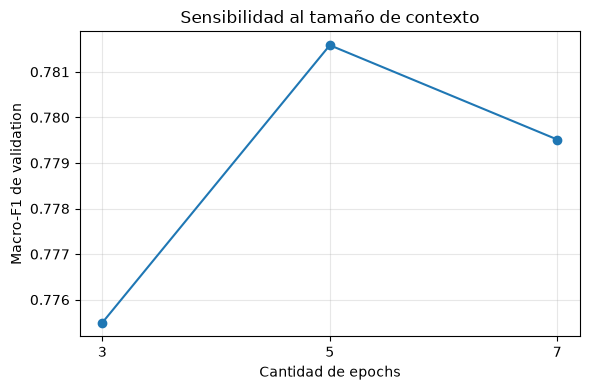

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(
    validation_summary["context_size"],
    validation_summary["val_macro_f1"],
    marker="o",
)

ax.set_xlabel("Cantidad de epochs")
ax.set_ylabel("Macro-F1 de validation")
ax.set_xticks(CONTEXT_SIZES)
ax.set_title("Sensibilidad al tamaño de contexto")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_PATH, dpi=150, bbox_inches="tight")
plt.show()

---
## 6. Comparación sobre test

Los tres modelos se evalúan sobre los mismos epochs centrales del holdout para medir la sensibilidad al tamaño de contexto.

La selección del contexto final sigue siendo la realizada con validation. Los resultados de test se usan para describir el comportamiento de cada ventana y comprobar si las diferencias se mantienen en sujetos no vistos.

In [13]:
test_rows = []
test_predictions = {}

for context_size, result in experiments.items():
    y_true, y_pred = predict_loader(
        result["model"],
        result["test_loader"],
    )

    test_predictions[context_size] = {
        "y_true": y_true,
        "y_pred": y_pred,
        "index": result["test_index"],
    }

    test_rows.append({
        "context_size": context_size,
        "seconds": context_size * 30,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
        ),
        "n_epochs": len(y_true),
    })

test_summary = (
    pd.DataFrame(test_rows)
    .sort_values("context_size")
    .reset_index(drop=True)
)

test_summary.to_csv(TEST_SUMMARY_PATH, index=False)

display(test_summary.round(4))
print(f"Contexto elegido por validation: {best_context} epochs")

,context_size,seconds,accuracy,balanced_accuracy,macro_f1,n_epochs
0,3,90,0.7868,0.7827,0.7684,26446
1,5,150,0.7833,0.7804,0.7673,26446
2,7,210,0.7854,0.7859,0.7731,26446


Contexto elegido por validation: 5 epochs


---
## 7. Resultados por clase y transiciones

Como análisis complementario, se revisa el F1 de cada etapa y el desempeño cerca de transiciones.

No se agregan nuevos modelos ni hiperparámetros en esta sección; solamente se desglosan las predicciones obtenidas en el experimento anterior.

In [14]:
class_rows = []

for context_size, result in test_predictions.items():
    y_true = result["y_true"]
    y_pred = result["y_pred"]

    for class_idx, stage_name in STAGE_MAP.items():
        class_rows.append({
            "context_size": context_size,
            "stage": stage_name,
            "f1": f1_score(
                y_true == class_idx,
                y_pred == class_idx,
                zero_division=0,
            ),
            "support": int((y_true == class_idx).sum()),
        })

class_results = pd.DataFrame(class_rows)

class_results.to_csv(
    CLASS_RESULTS_PATH,
    index=False,
)

class_pivot = class_results.pivot(
    index="stage",
    columns="context_size",
    values="f1",
).reindex(STAGE_NAMES)

display(class_pivot.round(4))

context_size,3,5,7
stage,,,
W,0.8373,0.8010,0.8244
N1,0.4987,0.5147,0.5175
N2,0.7993,0.8058,0.8004
N3,0.8456,0.8501,0.8542
REM,0.8612,0.8651,0.8692


In [15]:
transition_rows = []

for context_size, result in test_predictions.items():
    index_df = result["index"].copy()
    index_df["y_true"] = result["y_true"]
    index_df["y_pred"] = result["y_pred"]

    for subset_name, mask in [
        ("stable", ~index_df["is_transition"].astype(bool)),
        ("transition", index_df["is_transition"].astype(bool)),
    ]:
        subset = index_df.loc[mask]

        transition_rows.append({
            "context_size": context_size,
            "subset": subset_name,
            "n_epochs": len(subset),
            "accuracy": accuracy_score(
                subset["y_true"],
                subset["y_pred"],
            ),
            "balanced_accuracy": balanced_accuracy_score(
                subset["y_true"],
                subset["y_pred"],
            ),
            "macro_f1": f1_score(
                subset["y_true"],
                subset["y_pred"],
                average="macro",
            ),
        })

transition_results = pd.DataFrame(transition_rows)

transition_results.to_csv(
    TRANSITION_RESULTS_PATH,
    index=False,
)

display(
    transition_results.sort_values(
        ["subset", "context_size"]
    ).round(4)
)

,context_size,subset,n_epochs,accuracy,balanced_accuracy,macro_f1
0,3,stable,19400,0.8506,0.8107,0.7828
2,5,stable,19400,0.8432,0.8102,0.7768
4,7,stable,19400,0.8458,0.8196,0.7835
1,3,transition,7046,0.6113,0.6431,0.6172
3,5,transition,7046,0.6181,0.6326,0.6191
5,7,transition,7046,0.6192,0.6336,0.6239


---
## 8. Conclusiones

Se compararon ventanas temporales de 3, 5 y 7 epochs utilizando la misma arquitectura y los mismos epochs centrales.

El mejor resultado de validation se obtuvo con 5 epochs, con un Macro-F1 de 0.7816. Las diferencias entre los tres tamaños fueron pequeñas, y aumentar el contexto hasta 7 epochs no produjo una mejora consistente.

En test, la ventana de 7 epochs alcanzó el mayor Macro-F1 (0.7731), aunque la diferencia respecto de 5 epochs fue reducida. Por este motivo se mantiene la ventana de 5 epochs como configuración de referencia, ya que fue seleccionada a partir de validation y ofrece un buen compromiso entre desempeño y tamaño de contexto.

El análisis por clase muestra que N1, N3 y REM presentan una leve mejora al aumentar la ventana, mientras que W obtiene su mejor resultado con 3 epochs. En los epochs cercanos a transiciones también se observa una pequeña mejora con contextos más largos, aunque estos casos continúan siendo los más difíciles de clasificar.

En conjunto, los resultados indican que incorporar contexto temporal es útil, pero extender la ventana más allá de 5 epochs no aporta una mejora suficientemente clara como para justificar mayor complejidad.